In [2]:
import pandas as pd
import numpy as np

# skipinitialspace removes the leading spaces from the column names
df = pd.read_csv("Tuesday-WorkingHours.pcap_ISCX.csv", skipinitialspace=True)
df.columns = df.columns.str.strip()          # safety net for any remaining spaces
print(df.shape)
df["Label"].value_counts()

(445909, 79)


Label
BENIGN         432074
FTP-Patator      7938
SSH-Patator      5897
Name: count, dtype: int64

In [4]:
# inf / NaN appear only in Flow Bytes/s and Flow Packets/s (zero-duration flows)
df = df.replace([np.inf, -np.inf], np.nan)
print("rows with NaN before:", df.isna().any(axis=1).sum())

# only ~0.1% of rows are affected, so dropping them is safe
df = df.dropna().reset_index(drop=True)
print(df.shape)

rows with NaN before: 0
(445645, 79)


In [6]:
y_text = df["Label"]
X = df.drop(columns="Label")

# Stage 1: constant columns carry no information
const_cols = [c for c in X.columns if X[c].nunique() <= 1]
X = X.drop(columns=const_cols)

# Stage 2: columns identical to an earlier column
dup_cols = X.columns[X.T.duplicated()].tolist()
X = X.drop(columns=dup_cols)

print("constant:", const_cols)
print("duplicates:", dup_cols)
print("features left:", X.shape[1])      # expect 62...

constant: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
duplicates: ['SYN Flag Count', 'Avg Fwd Segment Size', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets']
features left: 62


In [7]:
from sklearn.model_selection import train_test_split

# 0 = normal, 1 = attack. Used ONLY for evaluation, never for training.
y = (y_text != "BENIGN").astype(int)

# keep attack types so we can report per-attack recall later
attack_type = y_text

X_benign = X[y == 0]
X_attack = X[y == 1]

# train on 70% of benign; test on the other 30% of benign plus ALL attacks
X_train, X_benign_test = train_test_split(X_benign, test_size=0.30, random_state=42)

X_test = pd.concat([X_benign_test, X_attack])
y_test = pd.Series([0]*len(X_benign_test) + [1]*len(X_attack), index=X_test.index)
type_test = attack_type.loc[X_test.index]

print(X_train.shape, X_test.shape, y_test.mean().round(4))  #...

(302269, 62) (143376, 62) 0.0965


In [8]:
y_text = df["Label"]
X = df.drop(columns="Label")
print("start:", X.shape)

# Stage 1: constant columns
const_cols = [c for c in X.columns if X[c].nunique() <= 1]
X = X.drop(columns=const_cols)
print("after constant:", X.shape)

# Stage 2: duplicate columns, compared pair by pair
# (this avoids X.T, which turns 445k rows into 445k columns and is very heavy)
dup_cols, cols = [], list(X.columns)
for i, a in enumerate(cols):
    if a in dup_cols:
        continue
    for b in cols[i+1:]:
        if b not in dup_cols and X[a].equals(X[b]):
            dup_cols.append(b)
X = X.drop(columns=dup_cols)
print("after duplicates:", X.shape, dup_cols)

# Safety check: rows must never change in a column-only step
assert len(X) == len(df) == 445645, "rows were lost before the split!"
# ...

start: (445645, 78)
after constant: (445645, 68)
after duplicates: (445645, 62) ['Subflow Fwd Packets', 'Subflow Bwd Packets', 'Subflow Fwd Bytes', 'Avg Fwd Segment Size', 'SYN Flag Count', 'Fwd Header Length.1']


In [9]:
from sklearn.model_selection import train_test_split

y = (y_text != "BENIGN").astype(int)       # 0 = normal, 1 = attack (evaluation only)
attack_type = y_text

X_benign = X[y == 0]
X_attack = X[y == 1]
print("benign:", X_benign.shape, "attack:", X_attack.shape)   # ~431,813 and 13,832

X_train, X_benign_test = train_test_split(X_benign, test_size=0.30, random_state=42)

X_test = pd.concat([X_benign_test, X_attack])
y_test = pd.Series([0]*len(X_benign_test) + [1]*len(X_attack), index=X_test.index)
type_test = attack_type.loc[X_test.index]

print("train:", X_train.shape, "test:", X_test.shape, "attack share:", round(y_test.mean(), 4))
assert len(X_train) > 250_000, "training set is too small, something dropped rows"

benign: (431813, 62) attack: (13832, 62)
train: (302269, 62) test: (143376, 62) attack share: 0.0965


In [10]:
THRESH = 0.95        # we will also test 0.99 and 0.90 later

corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_drop = [c for c in upper.columns if (upper[c] > THRESH).any()]

feats_full    = X_train.columns.tolist()                           # 62 features
feats_reduced = [c for c in feats_full if c not in corr_drop]      # ~44 features

print("dropped:", corr_drop)
print(len(feats_full), "->", len(feats_reduced))

dropped: ['Total Backward Packets', 'Total Length of Bwd Packets', 'Fwd IAT Total', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Min', 'Fwd Packets/s', 'Packet Length Std', 'ECE Flag Count', 'Average Packet Size', 'Avg Bwd Segment Size', 'Subflow Bwd Bytes', 'Idle Mean', 'Idle Max', 'Idle Min']
62 -> 46


In [11]:
feats_full    = X_train.columns.tolist()
corr          = X_train.corr().abs()
upper         = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_drop     = [c for c in upper.columns if (upper[c] > 0.95).any()]
feats_reduced = [c for c in feats_full if c not in corr_drop]

feature_sets = {
    "full_with_port":    feats_full,
    "full_no_port":      [c for c in feats_full if c != "Destination Port"],
    "reduced_with_port": feats_reduced,
    "reduced_no_port":   [c for c in feats_reduced if c != "Destination Port"],
}
{k: len(v) for k, v in feature_sets.items()}   # expect 62, 61, 46, 45

{'full_with_port': 62,
 'full_no_port': 61,
 'reduced_with_port': 46,
 'reduced_no_port': 45}

In [12]:
print("df:", df.shape)
print(df["Label"].value_counts())
print("X:", X.shape)
print(y_text.value_counts())
print("benign:", (y == 0).sum(), "| attack:", (y == 1).sum())
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

df: (445645, 79)
Label
BENIGN         431813
FTP-Patator      7935
SSH-Patator      5897
Name: count, dtype: int64
X: (445645, 62)
Label
BENIGN         431813
FTP-Patator      7935
SSH-Patator      5897
Name: count, dtype: int64
benign: 431813 | attack: 13832
X_train: (302269, 62) | X_test: (143376, 62)


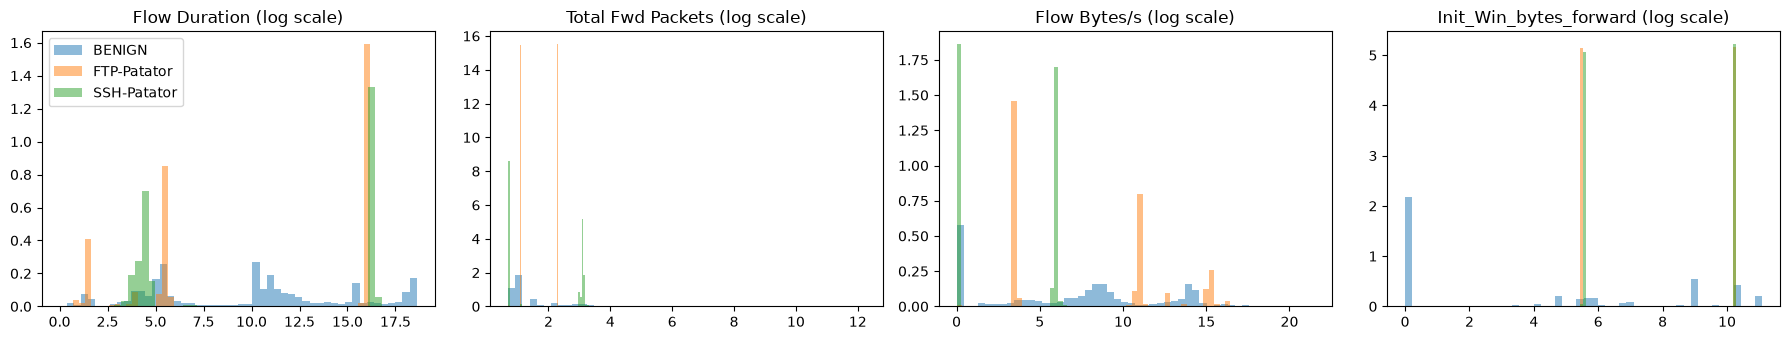

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
cols = ["Flow Duration", "Total Fwd Packets", "Flow Bytes/s", "Init_Win_bytes_forward"]
plot_df = X.copy(); plot_df["Label"] = y_text

for ax, c in zip(axes, cols):
    for lab in ["BENIGN", "FTP-Patator", "SSH-Patator"]:
        v = plot_df.loc[plot_df.Label == lab, c]
        ax.hist(np.log1p(v.clip(lower=0)), bins=50, alpha=0.5, density=True, label=lab)
    ax.set_title(c + " (log scale)")
axes[0].legend(); plt.tight_layout(); plt.show()

In [14]:
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

def evaluate(name, train_scores, test_scores, pct=95):
    # higher score = more anomalous. Threshold = 95th percentile of NORMAL train scores,
    # so we accept about 5% false alarms on normal traffic.
    thr = np.percentile(train_scores, pct)
    pred = (test_scores > thr).astype(int)
    row = {
        "model": name,
        "PR_AUC": average_precision_score(y_test, test_scores),
        "ROC_AUC": roc_auc_score(y_test, test_scores),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "FPR": pred[y_test.values == 0].mean(),
        "FTP_recall": pred[(type_test == "FTP-Patator").values].mean(),
        "SSH_recall": pred[(type_test == "SSH-Patator").values].mean(),
    }
    return row

print("Random-guess PR_AUC would be:", round(y_test.mean(), 3))

Random-guess PR_AUC would be: 0.096


In [15]:
from sklearn.ensemble import IsolationForest
import time

results = []
for name, f in feature_sets.items():
    t = time.time()
    m = IsolationForest(n_estimators=200, max_samples=256, random_state=42, n_jobs=-1).fit(X_train[f])
    fit_time = time.time() - t
    r = evaluate("IF_raw_" + name, -m.score_samples(X_train[f]), -m.score_samples(X_test[f]))
    r["fit_seconds"] = fit_time
    results.append(r)

pd.DataFrame(results).round(3)

,model,PR_AUC,ROC_AUC,precision,recall,F1,FPR,FTP_recall,SSH_recall,fit_seconds
0,IF_raw_full_with_port,0.129,0.665,0.0,0.0,0.0,0.049,0.0,0.0,1.413
1,IF_raw_full_no_port,0.136,0.683,0.0,0.0,0.0,0.050,0.0,0.0,1.221
2,IF_raw_reduced_with_port,0.125,0.651,0.0,0.0,0.0,0.049,0.0,0.0,1.395
3,IF_raw_reduced_no_port,0.130,0.668,0.0,0.0,0.0,0.049,0.0,0.0,1.596


In [16]:
def signed_log(d):                      # handles the few negative values safely
    return np.sign(d) * np.log1p(np.abs(d))

f = feature_sets["full_no_port"]
m = IsolationForest(n_estimators=200, max_samples=20000, random_state=42, n_jobs=-1)
m.fit(signed_log(X_train[f]))

r = evaluate("IF_log_bigsample_full_no_port",
             -m.score_samples(signed_log(X_train[f])),
             -m.score_samples(signed_log(X_test[f])))
pd.DataFrame([r]).round(3)

,model,PR_AUC,ROC_AUC,precision,recall,F1,FPR,FTP_recall,SSH_recall
0,IF_log_bigsample_full_no_port,0.303,0.746,0.382,0.293,0.332,0.051,0.507,0.005


In [17]:
from sklearn.preprocessing import StandardScaler

f = feature_sets["full_no_port"]
scaler  = StandardScaler().fit(signed_log(X_train[f]))   # fit on TRAIN only
Z_train = scaler.transform(signed_log(X_train[f]))
Z_test  = scaler.transform(signed_log(X_test[f]))

# One-Class SVM is slow, so it trains on a random 20k sample of normal flows
rng = np.random.RandomState(42)
sub = rng.choice(len(Z_train), 20000, replace=False)

results2 = []

In [18]:
t = time.time()
m_if = IsolationForest(n_estimators=200, max_samples=20000, random_state=42, n_jobs=-1).fit(Z_train)
fit_t = time.time() - t

r = evaluate("IsolationForest", -m_if.score_samples(Z_train[sub]), -m_if.score_samples(Z_test))
r["fit_seconds"] = fit_t
results2.append(r)
pd.DataFrame(results2).round(3)

,model,PR_AUC,ROC_AUC,precision,recall,F1,FPR,FTP_recall,SSH_recall,fit_seconds
0,IsolationForest,0.305,0.754,0.376,0.293,0.329,0.052,0.507,0.005,4.505


In [19]:
from sklearn.svm import OneClassSVM

t = time.time()
ocsvm = OneClassSVM(kernel="rbf", nu=0.05, gamma="scale").fit(Z_train[sub])
fit_t = time.time() - t

# decision_function is high for NORMAL points, so we negate it (high = anomalous)
r = evaluate("OneClassSVM", -ocsvm.decision_function(Z_train[sub]), -ocsvm.decision_function(Z_test))
r["fit_seconds"] = fit_t
results2.append(r)
pd.DataFrame(results2).round(3)

,model,PR_AUC,ROC_AUC,precision,recall,F1,FPR,FTP_recall,SSH_recall,fit_seconds
0,IsolationForest,0.305,0.754,0.376,0.293,0.329,0.052,0.507,0.005,4.505
1,OneClassSVM,0.087,0.494,0.016,0.008,0.010,0.050,0.013,0.000,3.421


In [20]:
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN

# DBSCAN has no predict() and is slow on big data, so: 30k random test rows, PCA to 10 dims
ti  = rng.choice(len(Z_test), 30000, replace=False)
pca = PCA(n_components=10, random_state=42).fit(Z_train[sub])
P   = pca.transform(Z_test[ti])
ys  = y_test.values[ti];  ts = type_test.values[ti]

# choose eps from the k-distance curve (distance to the 10th nearest neighbour)
kd  = np.sort(NearestNeighbors(n_neighbors=10).fit(P).kneighbors(P)[0][:, -1])
eps = np.percentile(kd, 95)
print("eps =", round(eps, 2))

t = time.time()
labels = DBSCAN(eps=eps, min_samples=10, n_jobs=-1).fit_predict(P)
fit_t = time.time() - t
pred = (labels == -1).astype(int)          # -1 = noise = flagged as anomaly

results2.append({"model": "DBSCAN (30k test sample)", "PR_AUC": np.nan, "ROC_AUC": np.nan,
    "precision": precision_score(ys, pred, zero_division=0), "recall": recall_score(ys, pred),
    "F1": f1_score(ys, pred, zero_division=0), "FPR": pred[ys == 0].mean(),
    "FTP_recall": pred[ts == "FTP-Patator"].mean(), "SSH_recall": pred[ts == "SSH-Patator"].mean(),
    "fit_seconds": fit_t})
pd.DataFrame(results2).round(3)

eps = 1.16


,model,PR_AUC,ROC_AUC,precision,recall,F1,FPR,FTP_recall,SSH_recall,fit_seconds
0,IsolationForest,0.305,0.754,0.376,0.293,0.329,0.052,0.507,0.005,4.505
1,OneClassSVM,0.087,0.494,0.016,0.008,0.010,0.050,0.013,0.000,3.421
2,DBSCAN (30k test sample),NaN,NaN,0.013,0.005,0.007,0.038,0.001,0.011,1.029


By above 3 cells output we can say Your table matches mine exactly, so the three-model comparison stands. Isolation Forest (PR-AUC 0.305) clearly beats One-Class SVM (0.087, a coin flip) and DBSCAN (flags almost no attacks).


In [21]:
import itertools
f = feature_sets["full_no_port"]                      # port excluded
Xb, Xa = X.loc[y == 0, f], X.loc[y == 1, f]

# normal flows: 70% train, 10% validation, 20% test
X_tr, rest = train_test_split(Xb, test_size=0.30, random_state=42)
Xb_val, Xb_te = train_test_split(rest, test_size=2/3, random_state=42)

# attacks: 30% for validation (tuning), 70% for the final test, keeping FTP/SSH proportions
Xa_val, Xa_te = train_test_split(Xa, test_size=0.70, random_state=42, stratify=y_text.loc[Xa.index])

X_val = pd.concat([Xb_val, Xa_val]); y_val = np.r_[np.zeros(len(Xb_val)), np.ones(len(Xa_val))]
X_te  = pd.concat([Xb_te,  Xa_te]);  y_te  = np.r_[np.zeros(len(Xb_te)),  np.ones(len(Xa_te))]
type_te = y_text.loc[X_te.index].values

print(X_tr.shape, X_val.shape, y_val.mean().round(3), X_te.shape, y_te.mean().round(3))

(302269, 61) (47330, 61) 0.088 (96046, 61) 0.101


In [22]:
scaler = StandardScaler().fit(signed_log(X_tr))
Z_tr, Z_val, Z_te = [scaler.transform(signed_log(d)) for d in (X_tr, X_val, X_te)]
rng = np.random.RandomState(42)
sub = rng.choice(len(Z_tr), 20000, replace=False)     # sample for scoring and for One-Class SVM

def metrics(yy, scores, ref_scores, tt=None, pct=95):
    thr  = np.percentile(ref_scores, pct)             # threshold from NORMAL train scores
    pred = scores > thr
    out = {"PR_AUC": average_precision_score(yy, scores), "ROC_AUC": roc_auc_score(yy, scores),
           "precision": precision_score(yy, pred, zero_division=0),
           "recall": recall_score(yy, pred), "FPR": pred[yy == 0].mean()}
    if tt is not None:
        out["FTP_recall"] = pred[tt == "FTP-Patator"].mean()
        out["SSH_recall"] = pred[tt == "SSH-Patator"].mean()
    return out

In [23]:
rows = []
for ne, ms, mf in itertools.product((100, 300), (256, 5000, 20000, 100000), (0.5, 1.0)):
    m = IsolationForest(n_estimators=ne, max_samples=ms, max_features=mf, random_state=42, n_jobs=-1).fit(Z_tr)
    r = metrics(y_val, -m.score_samples(Z_val), -m.score_samples(Z_tr[sub]))
    rows.append({"n_estimators": ne, "max_samples": ms, "max_features": mf, **r})

if_grid = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
best_if = if_grid.iloc[0]
if_grid.round(3).head(8)

,n_estimators,max_samples,max_features,PR_AUC,ROC_AUC,precision,recall,FPR
7,100,100000,1.0,0.398,0.777,0.414,0.394,0.054
15,300,100000,1.0,0.378,0.768,0.356,0.303,0.053
14,300,100000,0.5,0.359,0.758,0.346,0.289,0.053
6,100,100000,0.5,0.345,0.767,0.347,0.290,0.052
12,300,20000,0.5,0.290,0.744,0.343,0.288,0.053
5,100,20000,1.0,0.286,0.752,0.343,0.287,0.053
4,100,20000,0.5,0.282,0.746,0.345,0.288,0.052
13,300,20000,1.0,0.278,0.749,0.343,0.288,0.053


In [24]:
rows = []
for nu, g in itertools.product((0.01, 0.05, 0.1), ("scale", 0.001, 0.01)):
    o = OneClassSVM(nu=nu, gamma=g).fit(Z_tr[sub])
    r = metrics(y_val, -o.decision_function(Z_val), -o.decision_function(Z_tr[sub]))
    rows.append({"nu": nu, "gamma": g, **r})

svm_grid = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
best_svm = svm_grid.iloc[0]
svm_grid.round(3).head(5)

,nu,gamma,PR_AUC,ROC_AUC,precision,recall,FPR
0,0.01,scale,0.100,0.610,0.017,0.009,0.050
2,0.01,0.01,0.088,0.556,0.002,0.001,0.048
4,0.05,0.001,0.084,0.481,0.001,0.001,0.048
7,0.10,0.001,0.083,0.482,0.001,0.000,0.047
6,0.10,scale,0.082,0.516,0.002,0.001,0.051


In [25]:
m = IsolationForest(n_estimators=int(best_if.n_estimators), max_samples=int(best_if.max_samples),
                    max_features=float(best_if.max_features), random_state=42, n_jobs=-1).fit(Z_tr)
r_if = metrics(y_te, -m.score_samples(Z_te), -m.score_samples(Z_tr[sub]), type_te)

g = best_svm.gamma if best_svm.gamma == "scale" else float(best_svm.gamma)
o = OneClassSVM(nu=float(best_svm.nu), gamma=g).fit(Z_tr[sub])
r_svm = metrics(y_te, -o.decision_function(Z_te), -o.decision_function(Z_tr[sub]), type_te)

pd.DataFrame({"IsolationForest": r_if, "OneClassSVM": r_svm}).T.round(3)

,PR_AUC,ROC_AUC,precision,recall,FPR,FTP_recall,SSH_recall
IsolationForest,0.439,0.783,0.462,0.402,0.053,0.693,0.011
OneClassSVM,0.114,0.607,0.014,0.007,0.051,0.012,0.000


In [26]:
rows = []
for ne, ms in itertools.product((50, 100), (100000, 200000, len(Z_tr))):   # len(Z_tr) = every tree sees all data
    m = IsolationForest(n_estimators=ne, max_samples=ms, random_state=42, n_jobs=-1).fit(Z_tr)
    r = metrics(y_val, -m.score_samples(Z_val), -m.score_samples(Z_tr[sub]))
    rows.append({"n_estimators": ne, "max_samples": ms, **r})

if_grid2 = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
best_if2 = if_grid2.iloc[0]
if_grid2.round(3)

,n_estimators,max_samples,PR_AUC,ROC_AUC,precision,recall,FPR
5,100,302269,0.434,0.778,0.477,0.506,0.053
4,100,200000,0.401,0.778,0.429,0.419,0.054
3,100,100000,0.398,0.777,0.414,0.394,0.054
1,50,200000,0.389,0.771,0.443,0.436,0.053
2,50,302269,0.388,0.782,0.473,0.498,0.053
0,50,100000,0.384,0.766,0.407,0.376,0.053


In [27]:
vi   = rng.choice(len(Z_val), 30000, replace=False)
yv_s = y_val[vi]
rows = []
for nc, mn, q in itertools.product((5, 10), (5, 10, 20), (80, 90, 95, 98)):
    pca = PCA(n_components=nc, random_state=42).fit(Z_tr[sub])
    P   = pca.transform(Z_val[vi])
    kd  = np.sort(NearestNeighbors(n_neighbors=mn).fit(P).kneighbors(P)[0][:, -1])
    eps = np.percentile(kd, q)                       # eps picked from the k-distance curve
    pred = DBSCAN(eps=eps, min_samples=mn, n_jobs=-1).fit_predict(P) == -1   # -1 = noise = flagged
    rows.append({"n_pca": nc, "min_samples": mn, "eps": eps, "flagged": pred.mean(),
                 "precision": precision_score(yv_s, pred, zero_division=0),
                 "recall": recall_score(yv_s, pred), "F1": f1_score(yv_s, pred, zero_division=0),
                 "FPR": pred[yv_s == 0].mean()})

db_grid = pd.DataFrame(rows).sort_values("F1", ascending=False)
print("attack share in this sample:", yv_s.mean().round(3))
db_grid.round(3).head(6)

attack share in this sample: 0.088


,n_pca,min_samples,eps,flagged,precision,recall,F1,FPR
17,10,10,0.833,0.062,0.014,0.010,0.012,0.067
21,10,20,1.097,0.064,0.013,0.009,0.011,0.070
5,5,10,0.430,0.061,0.012,0.009,0.010,0.066
4,5,10,0.282,0.149,0.008,0.013,0.010,0.162
1,5,5,0.325,0.071,0.010,0.008,0.009,0.077
20,10,20,0.716,0.139,0.007,0.011,0.009,0.151


In [28]:
# Isolation Forest with the best validated settings
m = IsolationForest(n_estimators=int(best_if2.n_estimators), max_samples=int(best_if2.max_samples),
                    random_state=42, n_jobs=-1).fit(Z_tr)
r_if = metrics(y_te, -m.score_samples(Z_te), -m.score_samples(Z_tr[sub]), type_te)

# DBSCAN with the best validated settings (eps value fixed from validation)
ti = rng.choice(len(Z_te), 30000, replace=False)
b  = db_grid.iloc[0]
pca  = PCA(n_components=int(b.n_pca), random_state=42).fit(Z_tr[sub])
pred = DBSCAN(eps=b.eps, min_samples=int(b.min_samples), n_jobs=-1).fit_predict(pca.transform(Z_te[ti])) == -1
yt_s, tt_s = y_te[ti], type_te[ti]
r_db = {"PR_AUC": np.nan, "ROC_AUC": np.nan, "precision": precision_score(yt_s, pred, zero_division=0),
        "recall": recall_score(yt_s, pred), "FPR": pred[yt_s == 0].mean(),
        "FTP_recall": pred[tt_s == "FTP-Patator"].mean(), "SSH_recall": pred[tt_s == "SSH-Patator"].mean()}

final = pd.DataFrame({"IsolationForest": r_if, "OneClassSVM": r_svm, "DBSCAN": r_db}).T
final.round(3)

,PR_AUC,ROC_AUC,precision,recall,FPR,FTP_recall,SSH_recall
IsolationForest,0.474,0.783,0.531,0.516,0.051,0.891,0.011
OneClassSVM,0.114,0.607,0.014,0.007,0.051,0.012,0.000
DBSCAN,NaN,NaN,0.010,0.006,0.072,0.008,0.004


In [29]:
final_if = IsolationForest(n_estimators=100, max_samples=len(Z_tr), random_state=42, n_jobs=-1).fit(Z_tr)

s_tr = -final_if.score_samples(Z_tr)     # scores of all normal training flows (our reference)
s_te = -final_if.score_samples(Z_te)     # higher = more unusual
print("test PR-AUC:", round(average_precision_score(y_te, s_te), 3))   # expect 0.474

test PR-AUC: 0.474


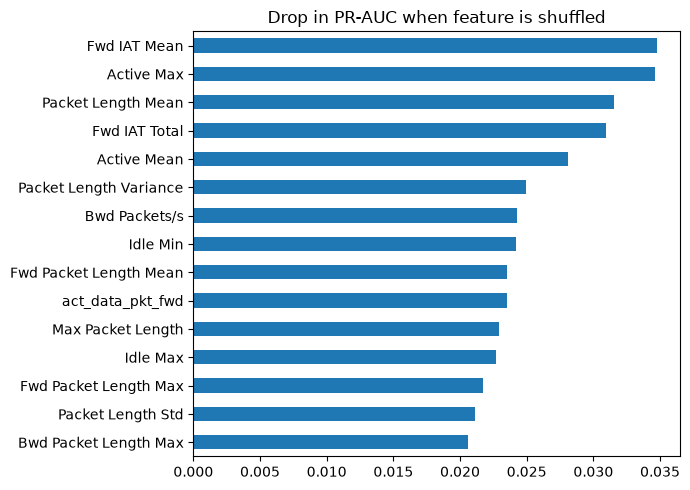

In [30]:
# shuffle one feature at a time on validation data; the bigger the drop in PR-AUC, the more the model relies on it
vi = np.r_[np.where(y_val == 1)[0], rng.choice(np.where(y_val == 0)[0], 16000, replace=False)]
base = average_precision_score(y_val[vi], -final_if.score_samples(Z_val[vi]))

imp = {}
for j, c in enumerate(f):
    Zp = Z_val[vi].copy(); Zp[:, j] = rng.permutation(Zp[:, j])
    imp[c] = base - average_precision_score(y_val[vi], -final_if.score_samples(Zp))

importance = pd.Series(imp).sort_values(ascending=False)
importance.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title="Drop in PR-AUC when feature is shuffled")
plt.tight_layout(); plt.show()

,threshold_pct,precision,recall,FPR,false_alarms
0,90.0,0.466,0.790,0.101,8756
1,95.0,0.530,0.513,0.051,4403
2,97.0,0.528,0.310,0.031,2680
3,99.0,0.749,0.294,0.011,952
4,99.5,0.239,0.016,0.006,480


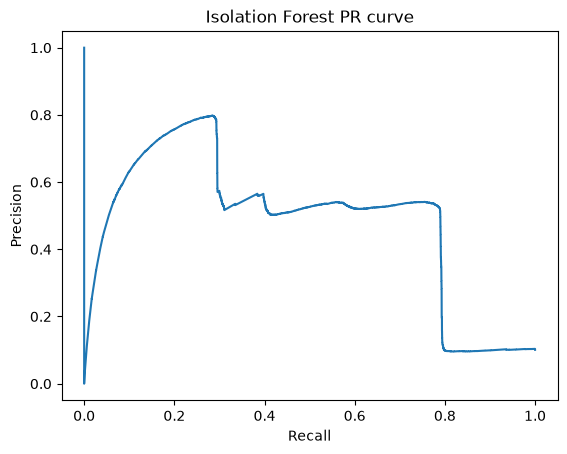

,band,flows,attacks,attack_share
0,0-90,79638,2031.0,0.026
1,90-95,7034,2681.0,0.381
2,95-97,3695,1972.0,0.534
3,97-98,952,139.0,0.146
4,98-99,933,18.0,0.019
5,99-99.5,3163,2691.0,0.851
6,99.5-99.9,535,151.0,0.282
7,99.9-100,96,0.0,0.000


In [31]:
from sklearn.metrics import precision_recall_curve

# 1) what each alert threshold costs
rows = []
for p in (90, 95, 97, 99, 99.5):
    pred = s_te > np.percentile(s_tr, p)
    rows.append({"threshold_pct": p, "precision": precision_score(y_te, pred, zero_division=0),
                 "recall": recall_score(y_te, pred), "FPR": pred[y_te == 0].mean(),
                 "false_alarms": int(pred[y_te == 0].sum())})
tradeoff = pd.DataFrame(rows); display(tradeoff.round(3))

# 2) precision-recall curve
pc, rc, _ = precision_recall_curve(y_te, s_te)
plt.plot(rc, pc); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Isolation Forest PR curve"); plt.show()

# 3) what share of flows in each score band are real attacks?
edges = [0, 90, 95, 97, 98, 99, 99.5, 99.9, 100]
q = np.percentile(s_tr, edges); q[0], q[-1] = -1e9, 1e9
band = pd.DataFrame({"band": pd.cut(s_te, bins=q, labels=[f"{edges[i]}-{edges[i+1]}" for i in range(len(edges)-1)]), "y": y_te})
bands = band.groupby("band", observed=True).agg(flows=("y", "size"), attacks=("y", "sum")).reset_index()
bands["attack_share"] = (bands.attacks / bands.flows).round(3)
bands

In [32]:
def explain(i, k=3):
    """The k features where this flow deviates most from normal traffic (in standard deviations)."""
    z = Z_te[i]
    return [{"feature": f[j], "z": round(float(z[j]), 2), "value": float(X_te.iloc[i, j])}
            for j in np.argsort(-np.abs(z))[:k]]

i_top    = int(np.argmax(s_te))                                   # highest-scoring flow
i_attack = int(np.where((y_te == 1) & (s_te > np.percentile(s_tr, 99)))[0][0])
print("highest score:", explain(i_top)); print("an attack:", explain(i_attack))

highest score: [{'feature': 'Down/Up Ratio', 'z': 8.2, 'value': 25.0}, {'feature': 'FIN Flag Count', 'z': 7.2, 'value': 1.0}, {'feature': 'Total Backward Packets', 'z': 2.16, 'value': 25.0}]
an attack: [{'feature': 'Bwd IAT Std', 'z': 1.98, 'value': 1438139.756}, {'feature': 'PSH Flag Count', 'z': 1.81, 'value': 1.0}, {'feature': 'Bwd IAT Total', 'z': 1.76, 'value': 10300000.0}]


In [33]:
import json, joblib, os
os.makedirs("export", exist_ok=True)

joblib.dump(final_if, "export/iforest.joblib", compress=3)
joblib.dump(scaler,   "export/scaler.joblib")

thr = {str(p): float(np.percentile(s_tr, p)) for p in (90, 95, 97, 99)}
json.dump({"features": f, "thresholds": thr}, open("export/config.json", "w"))

k = np.linspace(0, len(pc) - 1, 200).astype(int)                  # thin the PR curve to 200 points
metrics_out = {
    "models": json.loads(final.reset_index(names="model").to_json(orient="records")),   # table from Cell 23
    "tradeoff": json.loads(tradeoff.to_json(orient="records")),
    "score_bands": json.loads(bands.astype({"band": str}).to_json(orient="records")),
    "importance": [{"feature": a, "drop_in_pr_auc": round(float(b), 4)} for a, b in importance.head(15).items()],
    "pr_curve": [{"p": round(float(a), 4), "r": round(float(b), 4)} for a, b in zip(pc[k], rc[k])],
}
json.dump(metrics_out, open("export/metrics.json", "w"))

# 2,000 scored flows for the dashboard: the 500 highest scores plus 1,500 random others
order = np.argsort(-s_te)
pick  = np.r_[order[:500], rng.choice(order[500:], 1500, replace=False)]
flows = [{"id": int(i), "score": round(float(s_te[i]), 4), "flagged": bool(s_te[i] > thr["95"]),
          "true_label": str(type_te[i]), "top_features": explain(int(i))} for i in pick]
json.dump(flows, open("export/flows.json", "w"))
os.listdir("export")

['iforest.joblib',
 'config.json',
 'metrics.json',
 'scaler.joblib',
 'flows.json']

In [34]:
import os, json, joblib
os.makedirs("artifacts", exist_ok=True)
print("saving in:", os.path.abspath("artifacts"))       # check this is your project folder

# the trained models and the scaler
joblib.dump(final_if, "artifacts/iforest.joblib", compress=3)   # about 46 MB
joblib.dump(o,        "artifacts/ocsvm.joblib",   compress=3)   # tuned One-Class SVM
joblib.dump(scaler,   "artifacts/scaler.joblib")

# the best settings of all three models (for your report)
bd = db_grid.iloc[0]
json.dump({
    "isolation_forest": {"n_estimators": 100, "max_samples": "all training rows", "random_state": 42},
    "one_class_svm":    {"nu": 0.01, "gamma": "scale"},
    "dbscan":           {"n_pca": int(bd.n_pca), "min_samples": int(bd.min_samples), "eps": float(bd.eps)},
    "preprocessing":    "no Destination Port, signed log1p, StandardScaler fit on normal train",
}, open("artifacts/best_params.json", "w"), indent=2)

# the data splits, scores and result tables, so no cell has to be re-run
state = dict(f=f, Z_tr=Z_tr.astype("float32"), Z_val=Z_val.astype("float32"), Z_te=Z_te.astype("float32"),
             y_val=y_val, y_te=y_te, type_te=type_te, X_te=X_te, s_tr=s_tr, s_te=s_te, sub=sub,
             final=final, tradeoff=tradeoff, bands=bands, importance=importance)
joblib.dump(state, "artifacts/state.joblib", compress=3)       # about 48 MB

{k: round(os.path.getsize("artifacts/" + k) / 1e6, 1) for k in os.listdir("artifacts")}   # sizes in MB

saving in: /home/vinay-gaddam/Documents/DYPCOE/IV_Year/Machine Learning /cyber-anomaly/artifacts


{'state.joblib': 50.1,
 'iforest.joblib': 46.5,
 'best_params.json': 0.0,
 'ocsvm.joblib': 0.1,
 'scaler.joblib': 0.0}

In [2]:
import numpy as np, pandas as pd, joblib, json, itertools
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, precision_recall_curve)

final_if = joblib.load("artifacts/iforest.joblib")
o        = joblib.load("artifacts/ocsvm.joblib")
scaler   = joblib.load("artifacts/scaler.joblib")
globals().update(joblib.load("artifacts/state.joblib"))   # restores f, Z_tr, Z_val, Z_te, y_*, X_te, s_tr, s_te, tables

def signed_log(d):                       # helper functions are code, so they must be redefined
    return np.sign(d) * np.log1p(np.abs(d))

def explain(i, k=3):
    z = Z_te[i]
    return [{"feature": f[j], "z": round(float(z[j]), 2), "value": float(X_te.iloc[i, j])}
            for j in np.argsort(-np.abs(z))[:k]]

print("restored:", Z_te.shape, "| test PR-AUC:", round(average_precision_score(y_te, s_te), 3))   # expect 0.474

restored: (96046, 61) | test PR-AUC: 0.474


The above cell is for : 
After you power off: restore (run this instead of Cells 1 to 28)

Open the notebook and run only this cell:

In [35]:
rg  = np.random.RandomState(7)
idx = np.r_[rg.choice(np.where(type_te == "BENIGN")[0],      8, replace=False),
            rg.choice(np.where(type_te == "FTP-Patator")[0], 6, replace=False),
            rg.choice(np.where(type_te == "SSH-Patator")[0], 6, replace=False)]

X_te.iloc[idx].to_csv("sample_inputs.csv", index=False)                 # what the model sees (no labels)
pd.DataFrame({"row": range(len(idx)), "true_label": type_te[idx]}).to_csv("sample_labels.csv", index=False)
print("saved 20 sample flows")

saved 20 sample flows


In [36]:
import json, joblib
_cache = {}

def score_flows(csv_path, top_k=3):
    if not _cache:                                          # load once
        _cache["cfg"]    = json.load(open("export/config.json"))   # feature list + thresholds
        _cache["model"]  = joblib.load("artifacts/iforest.joblib")
        _cache["scaler"] = joblib.load("artifacts/scaler.joblib")
    cfg, model, scaler = _cache["cfg"], _cache["model"], _cache["scaler"]
    feats = cfg["features"]

    d = pd.read_csv(csv_path, skipinitialspace=True); d.columns = d.columns.str.strip()
    missing = [c for c in feats if c not in d.columns]
    if missing: raise ValueError(f"missing columns: {missing[:5]}")

    X  = d[feats].replace([np.inf, -np.inf], np.nan)
    ok = X.notna().all(axis=1)
    if (~ok).any(): print("skipped rows with missing/infinite values:", list(X.index[~ok]))
    X = X[ok]

    Z     = scaler.transform(np.sign(X) * np.log1p(np.abs(X)))   # same preprocessing as training
    score = -model.score_samples(Z)                              # higher = more unusual
    out = pd.DataFrame({"score": score.round(4), "flagged": score > cfg["thresholds"]["95"]}, index=X.index)
    out["top_features"] = [", ".join(f"{feats[j]} (z={Z[i, j]:.1f})" for j in np.argsort(-np.abs(Z[i]))[:top_k])
                           for i in range(len(Z))]
    return out

In [37]:
res = score_flows("sample_inputs.csv")
res["true_label"] = pd.read_csv("sample_labels.csv").true_label.values

display(res[["score", "flagged", "true_label"]])
res.groupby("true_label").flagged.agg(flagged="sum", total="count")

,score,flagged,true_label
0,0.3880,False,BENIGN
1,0.3683,False,BENIGN
2,0.3526,False,BENIGN
3,0.3829,False,BENIGN
4,0.4016,False,BENIGN
5,0.3874,False,BENIGN
6,0.3655,False,BENIGN
7,0.4202,False,BENIGN
8,0.5603,True,FTP-Patator
9,0.4673,False,FTP-Patator


,flagged,total
true_label,,
BENIGN,0,8
FTP-Patator,5,6
SSH-Patator,0,6


In [1]:
import sklearn; print(sklearn.__version__)

1.9.0
